# Banking Fraud & Transaction Intelligence
**End-to-end Data Analytics Portfolio — PaySim real-dataset mode (synthetic transactions)** | Python, pandas, SQL JOINs, transparent rule-based risk monitoring, Tableau.

**Dataset notice:** Demo records are illustrative. PaySim is a separate downloadable synthetic dataset. This notebook does not imply access to a real bank’s data.

## 01 — Setup and project paths
Run from the repository root. The notebook calls the same functions as the command-line pipeline.

In [1]:
from pathlib import Path
import sys, json, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / "src" / "analysis.py").exists():
    raise FileNotFoundError("Open Jupyter in the repository root")
sys.path.insert(0, str(ROOT / "src"))
import analysis as a
pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/tsov/Desktop/project 2 part 2/Banking_Fraud_Transaction_Intelligence


## 02 — Load the downloaded PaySim CSV (real dataset mode)

This notebook now defaults to **PaySim**, not demo data. It searches the project `data/` folder and your Mac `~/Downloads` folder for `PS_20174392719_1491204439457_log.csv`. A missing file produces a clear instruction rather than silently switching to demo data.

To keep Mac memory usage manageable, `ROW_LIMIT = 300_000` analyzes the **first 300,000 rows**, not a representative random sample. Increase it only if your Mac can handle the memory. PaySim is a **synthetic** dataset, not actual bank customer records.

In [2]:
# REAL PAYSIM DATA
USE_DEMO = False
ROW_LIMIT = 300_000  # First 300,000 rows

from pathlib import Path

def locate_paysim_csv():
    filename = "PS_20174392719_1491204439457_log.csv"

    candidates = [
        Path("/Users/tsov/Desktop/data") / filename,
        ROOT / "data" / filename,
        ROOT / filename,
        Path.home() / "Downloads" / filename,
        Path.home() / "Desktop" / filename,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    for folder in [
        Path("/Users/tsov/Desktop/data"),
        ROOT / "data",
        Path.home() / "Downloads"
    ]:
        if folder.is_dir():
            matches = sorted(
                p for p in folder.glob("PS_20174392719_1491204439457_log*")
                if p.is_file() and p.suffix.lower() == ".csv"
            )
            if matches:
                return matches[0]

    raise FileNotFoundError(
        "PaySim CSV not found. Check /Users/tsov/Desktop/data/"
    )

PAYSIM_CSV = locate_paysim_csv()

print("PaySim file:", PAYSIM_CSV)

raw, provenance = a.load_data(
    PAYSIM_CSV,
    demo=False,
    limit=ROW_LIMIT
)

print("Source:", provenance)
print("Rows and columns:", raw.shape)

display(raw.head())

PaySim file: /Users/tsov/Desktop/data/PS_20174392719_1491204439457_log.csv
Source: PaySim dataset: PS_20174392719_1491204439457_log.csv (first 300,000 rows)
Rows and columns: (300000, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## 03 — Data dictionary and schema
`step`: simulation hour; `type`: transaction category; `amount`: dataset units; `nameOrig`/`nameDest`: account IDs; balances: before/after transaction; `isFraud`: simulation label; `isFlaggedFraud`: PaySim built-in rule.

In [3]:
display(pd.DataFrame({"dtype":raw.dtypes.astype(str),"missing":raw.isna().sum(),"unique":raw.nunique()}))

,dtype,missing,unique
step,int64,0,15
type,object,0,5
amount,float64,0,296757
nameOrig,object,0,299982
oldbalanceOrg,float64,0,148653
newbalanceOrig,float64,0,135631
nameDest,object,0,134668
oldbalanceDest,float64,0,171231
newbalanceDest,float64,0,80080
isFraud,int64,0,2


## 04 — Data cleaning and validation
Remove exact duplicates, coerce numeric fields, reject missing essential identifiers and invalid amounts; retain QA counts.

In [4]:
df, qa = a.validate_and_clean(raw)
print(qa)
display(df.head())

{'raw_rows': 300000, 'clean_rows': 300000, 'removed_rows': 0, 'duplicate_or_invalid_removed': 0}


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,transaction_id,day,hour,is_merchant,amount_band,origin_balance_delta,balance_difference,rule_high_amount,rule_low_pre_balance,rule_transfer,risk_score,risk_tier,rule_alert
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,1,1,0,1,1k–10k,9839.64,1.455192e-11,0,0,0,0,Low,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,2,1,0,1,1k–10k,1864.28,1.136868e-12,0,0,0,0,Low,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,3,1,0,0,<=1k,181.00,0.000000e+00,0,0,1,1,Medium,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,4,1,0,0,<=1k,181.00,0.000000e+00,0,0,1,1,Medium,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,5,1,0,1,10k–50k,11668.14,0.000000e+00,0,0,0,0,Low,0


## 05 — Descriptive statistics
Compare median and mean amounts; the mean can be pulled upward by large transactions.

In [5]:
display(df[["amount","oldbalanceOrg","newbalanceOrig"]].describe(percentiles=[.25,.5,.75,.9,.95,.99]).T)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
amount,300000.0,176170.826423,3.016055e+05,0.3,12741.25,77699.525,231478.9475,410999.444,586847.610,1.580466e+06,10000000.00
oldbalanceOrg,300000.0,885567.577106,2.849254e+06,0.0,0.00,18569.000,183687.4750,2230759.157,6030385.068,1.531439e+07,38939424.03
newbalanceOrig,300000.0,904281.974529,2.886694e+06,0.0,0.00,0.000,221479.7075,2359597.927,6179721.257,1.548012e+07,38946233.02


## 06 — Transaction category analysis

In [6]:
by_type = df.groupby("type",as_index=False).agg(transactions=("transaction_id","size"),volume=("amount","sum"),fraud=("isFraud","sum"),alerts=("rule_alert","sum"))
by_type["fraud_rate_pct"] = 100*by_type.fraud/by_type.transactions
display(by_type.sort_values("volume",ascending=False))

,type,transactions,volume,fraud,alerts,fraud_rate_pct
1,CASH_OUT,105401,2.103662e+10,93,73243,0.000797
4,TRANSFER,24905,1.914814e+10,88,22381,0.003855
0,CASH_IN,63408,1.141453e+10,0,16366,0.000000
3,PAYMENT,104056,1.234202e+09,0,0,0.000000
2,DEBIT,2230,1.776672e+07,0,14,0.000000


## 07 — Simulated daily activity
Days are derived from `step` and are not actual calendar dates.

,day,transactions,volume,fraud
0,1,300000,5.285125e+10,181


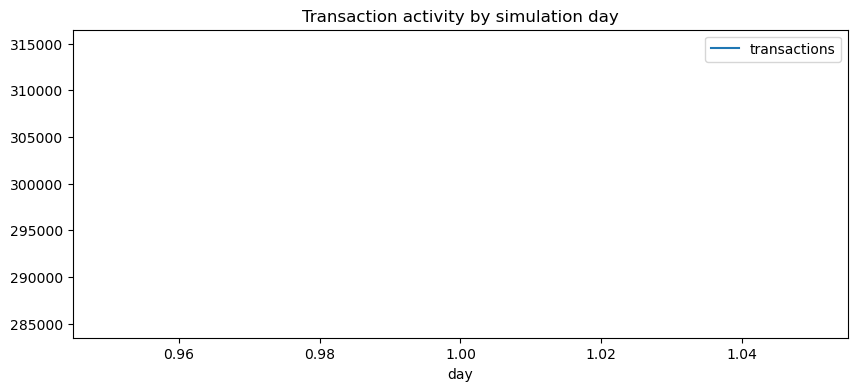

In [7]:
daily = df.groupby("day",as_index=False).agg(transactions=("transaction_id","size"),volume=("amount","sum"),fraud=("isFraud","sum"))
display(daily.head(10))
daily.plot(x="day",y="transactions",figsize=(10,4),title="Transaction activity by simulation day"); plt.show()

## 08 — Fraud labels vs alert flags
Fraud labels describe the simulation; an alert is only a signal for review.

In [8]:
display(pd.crosstab(df["isFraud"],df["rule_alert"],rownames=["Synthetic label"],colnames=["Our rule alert"],margins=True))

Our rule alert,0,1,All
Synthetic label,,,
0,187902,111917,299819
1,94,87,181
All,187996,112004,300000


## 09 — Explainable anomaly indicators
We intentionally avoid machine learning. Score: 2 for amount ≥100,000; +1 when amount exceeds pre-transaction origin balance; +1 for TRANSFER/CASH_OUT. Alert if score ≥3. This is not a validated banking policy.

In [9]:
display(df[["amount","type","oldbalanceOrg","rule_high_amount","rule_low_pre_balance","rule_transfer","risk_score","risk_tier","rule_alert"]].sample(10,random_state=3))

,amount,type,oldbalanceOrg,rule_high_amount,rule_low_pre_balance,rule_transfer,risk_score,risk_tier,rule_alert
27570,4020.02,PAYMENT,1762519.07,0,0,0,0,Low,0
26272,187454.98,CASH_OUT,20892.00,1,1,1,4,High,1
288783,1690178.14,TRANSFER,0.00,1,1,1,4,High,1
78270,5355.21,PAYMENT,447254.50,0,0,0,0,Low,0
54990,38396.43,CASH_IN,8111814.21,0,0,0,0,Low,0
148430,53282.01,CASH_IN,235570.00,0,0,0,0,Low,0
227665,135145.15,CASH_OUT,0.00,1,1,1,4,High,1
205163,58023.36,PAYMENT,30248.00,0,1,0,1,Medium,0
269502,574853.87,CASH_IN,14720.00,1,1,0,3,High,1
74125,538022.92,CASH_IN,664821.16,1,0,0,2,Medium,0


## 10 — Rule-based risk distribution

,risk_tier,transactions,labeled_fraud,alerts
0,High,112004,87,112004
1,Low,75701,0,0
2,Medium,112295,94,0


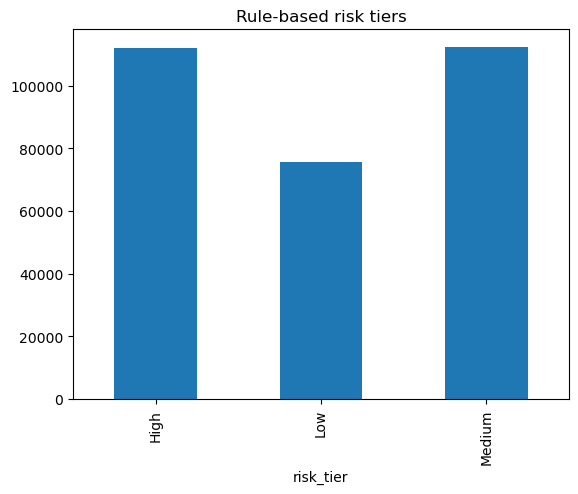

In [10]:
risk_summary = df.groupby("risk_tier",as_index=False).agg(transactions=("transaction_id","size"),labeled_fraud=("isFraud","sum"),alerts=("rule_alert","sum"))
display(risk_summary)
risk_summary.plot.bar(x="risk_tier",y="transactions",legend=False,title="Rule-based risk tiers"); plt.show()

## 11 — Alert evaluation
Precision = TP/(TP+FP), Recall = TP/(TP+FN). With rare fraud, the raw accuracy alone is misleading.

In [11]:
summary = a.summarize(df,provenance,qa)
display(pd.DataFrame([summary["confusion_matrix"]]))
print("Precision:",summary["precision"],"Recall:",summary["recall"])

,TP,FP,FN,TN
0,87,111917,94,187902


Precision: 0.0008 Recall: 0.4807


## 12 — Accounts and transaction-type dimensions
Derive normalized lookup tables from observed account IDs. These are not real customer demographic profiles.

In [12]:
accounts, types = a.create_dimensions(df)
display(accounts.head(),types)
print("Distinct accounts:",len(accounts))

,account_id,account_type
0,C1000012640,Customer-like
1,C1000028246,Customer-like
2,C1000035425,Customer-like
3,C1000037689,Customer-like
4,C1000038153,Customer-like


,type,type_group
0,CASH_IN,Other
1,CASH_OUT,Movement
2,DEBIT,Other
3,PAYMENT,Other
4,TRANSFER,Movement


Distinct accounts: 434649


## 13 — SQL database construction
The pipeline writes three SQLite tables: `transactions`, `accounts`, `transaction_types`.

In [13]:
database = a.sql_analysis(df,accounts,types)
print("SQLite file:",database)

SQL 01_executive_kpis.sql: 1 rows
SQL 02_type_risk_join.sql: 5 rows
SQL 03_accounts_left_join.sql: 1,000 rows
SQL 04_having_high_activity.sql: 0 rows
SQL 05_risk_case_when.sql: 3 rows
SQL 06_window_daily_ranking.sql: 1 rows
SQL 07_alert_evaluation.sql: 1 rows
SQLite file: /Users/tsov/Desktop/project 2 part 2/Banking_Fraud_Transaction_Intelligence/outputs/banking_intelligence.sqlite


## 14 — SQL INNER JOIN: transaction type performance

In [14]:
with sqlite3.connect(database) as conn:
    sql = (ROOT/"sql"/"02_type_risk_join.sql").read_text()
    display(pd.read_sql_query(sql,conn))

,type,type_group,transactions,total_amount,labeled_fraud,alerts,labeled_fraud_pct
0,CASH_OUT,Movement,105401,2.103662e+10,93,73243,0.0882
1,PAYMENT,Other,104056,1.234202e+09,0,0,0.0000
2,CASH_IN,Other,63408,1.141453e+10,0,16366,0.0000
3,TRANSFER,Movement,24905,1.914814e+10,88,22381,0.3533
4,DEBIT,Other,2230,1.776672e+07,0,14,0.0000


## 15 — SQL LEFT JOIN: account coverage
LEFT JOIN retains accounts even if they have no outgoing activity.

In [15]:
with sqlite3.connect(database) as conn:
    sql = (ROOT/"sql"/"03_accounts_left_join.sql").read_text()
    display(pd.read_sql_query(sql,conn).head(12))

,account_id,account_type,outgoing_count,outgoing_amount,labeled_fraud,alerts
0,C351297720,Customer-like,1,10000000.00,1,1
1,C7162498,Customer-like,1,10000000.00,1,1
2,C890128330,Customer-like,1,6419835.27,0,1
3,C135832352,Customer-like,1,6188514.81,1,1
4,C686187434,Customer-like,1,6188514.81,1,1
5,C2022065686,Customer-like,1,6072832.27,0,1
6,C293394374,Customer-like,1,5677662.29,0,1
7,C1588880909,Customer-like,1,5460002.91,1,1
8,C666654362,Customer-like,1,5460002.91,1,1
9,C574755786,Customer-like,1,5082871.40,0,1


## 16 — SQL HAVING: frequently active accounts

In [16]:
with sqlite3.connect(database) as conn:
    display(pd.read_sql_query((ROOT/"sql"/"04_having_high_activity.sql").read_text(),conn).head(10))

,account_id,transactions,total_amount,alerts


## 17 — SQL CASE WHEN: risk segments

In [17]:
with sqlite3.connect(database) as conn:
    display(pd.read_sql_query((ROOT/"sql"/"05_risk_case_when.sql").read_text(),conn))

,risk_segment,transactions,labeled_fraud,labeled_fraud_pct
0,High,112004,87,0.0777
1,Medium,112295,94,0.0837
2,Low,75701,0,0.0000


## 18 — SQL CTE + window function: daily ranking and cumulative activity

In [18]:
with sqlite3.connect(database) as conn:
    display(pd.read_sql_query((ROOT/"sql"/"06_window_daily_ranking.sql").read_text(),conn).head(12))

,day,transactions,labeled_fraud,amount,activity_rank,cumulative_transactions
0,1,300000,181,5.285125e+10,1,300000


## 19 — Account-level monitoring

In [19]:
account_activity = df.groupby("nameOrig",as_index=False).agg(n_transactions=("transaction_id","size"),total_amount=("amount","sum"),rule_alerts=("rule_alert","sum"))
display(account_activity.sort_values("total_amount",ascending=False).head(15))

,nameOrig,n_transactions,total_amount,rule_alerts
255547,C7162498,1,10000000.00,1
198797,C351297720,1,10000000.00,1
282762,C890128330,1,6419835.27,1
55556,C135832352,1,6188514.81,1
250932,C686187434,1,6188514.81,1
158007,C2022065686,1,6072832.27,1
189841,C293394374,1,5677662.29,1
91024,C1588880909,1,5460002.91,1
248002,C666654362,1,5460002.91,1
233755,C574755786,1,5082871.40,1


## 20 — Time-of-day alert heatmap source

In [20]:
hourly = df.groupby(["day","hour"],as_index=False).agg(n_transactions=("transaction_id","size"),alerts=("rule_alert","sum"))
display(hourly.head())

,day,hour,n_transactions,alerts
0,1,0,2708,461
1,1,1,1014,127
2,1,2,552,42
3,1,3,565,71
4,1,4,665,59


## 21 — Data quality checks

In [21]:
assert df.transaction_id.is_unique
assert df.amount.ge(0).all()
assert df.isFraud.isin([0,1]).all()
assert df.rule_alert.isin([0,1]).all()
assert df.risk_score.between(0,4).all()
assert df.groupby("type").size().sum()==len(df)
print("All six checks passed")

All six checks passed


## 22 — Export Tableau-ready data
The export contains all necessary fields for three dashboard pages. Tableau build instructions are in `TABLEAU_BUILD_GUIDE.md`.

In [22]:
for directory in [a.OUT,a.TAB]:directory.mkdir(parents=True,exist_ok=True)
tableau_daily, tableau_types = a.create_tableau_exports(df,accounts,types)
a.charts(df,tableau_daily,tableau_types)
a.write_report(summary,df)
print("Tableau CSV files:")
for f in sorted(a.TAB.glob("*.csv")):print(" -",f.name,round(f.stat().st_size/1e6,2),"MB")

Tableau CSV files:
 - accounts.csv 10.56 MB
 - daily_metrics.csv 0.0 MB
 - risk_heatmap.csv 0.0 MB
 - transaction_types.csv 0.0 MB
 - transactions_dashboard.csv 25.21 MB
 - type_metrics.csv 0.0 MB


## 23 — Executive findings
Read the generated `RESULTS.md` for data-dependent results. Do not quote demo metrics as real banking or PaySim findings.

In [23]:
print((ROOT/"RESULTS.md").read_text()[:3500])

# Banking Fraud & Transaction Intelligence — Results

**Dataset:** PaySim dataset: PS_20174392719_1491204439457_log.csv (first 300,000 rows)
**Transactions:** 300,000
**Labeled fraud cases:** 181 (0.0603%)
**Rule alerts:** 112,004 (37.3347%)
**Rule precision:** 0.0008 | **Recall:** 0.4807

## Breakdown by type

| type     |   transactions |   fraud |   alerts |   fraud_rate_pct |
|:---------|---------------:|--------:|---------:|-----------------:|
| CASH_IN  |          63408 |       0 |    16366 |            0     |
| CASH_OUT |         105401 |      93 |    73243 |            0.001 |
| DEBIT    |           2230 |       0 |       14 |            0     |
| PAYMENT  |         104056 |       0 |        0 |            0     |
| TRANSFER |          24905 |      88 |    22381 |            0.004 |

## Interpretation and limitations

- A rule alert is **not** proof of fraud. Labels are synthetic simulation outcomes.
- Risk thresholds are illustrative, not validated bank policy.
- PaySim step 

## 24 — Limitations and reproducibility
- Synthetic data only; no real bank or personal records.
- Demo is generated by this project, not downloaded PaySim.
- Thresholds are illustrative and not optimized or validated.
- Alert ≠ fraud; no causal claims.
- `step` is simulation time, not a timestamp.
- First-N-row limiting may bias rates.
- No completed `.twbx` is included; use the detailed Tableau guide to assemble and publish.
- No web scraping is claimed; this dataset is a CSV source.

**Next:** Build three Tableau dashboard pages and publish their link.
- This notebook defaults to the first 300,000 PaySim rows; this subset is not a random sample or full-population estimate.
